# DataCo Supply Chain Performance & Profitability Analytics

## Business Problem

DataCo operates across multiple markets, products, customers and shipping modes. The company needs to understand what drives sales, which products and markets are profitable, how shipping performance varies, where shipment delays occur, how customer segments perform, and whether operational performance is associated with profitability.

## Main Project Question

How can DataCo's sales, customer, product and shipping data be analyzed to evaluate commercial performance, identify shipment delay patterns, and understand their relationship with profitability?

The word relationship is used deliberately instead of impact or cause. This dataset is observational, so no operational factor is claimed to cause a financial outcome without an appropriate causal design.

## Understanding the Raw Files

This project uses two files from the Kaggle DataCo Smart Supply Chain dataset:

DataCoSupplyChainDataset.csv, the transactional table, 180,519 rows and 53 columns.
DescriptionDataCoSupplyChain.csv, the data dictionary explaining what each of the 53 fields means.



In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import plotly.express as px
import plotly.graph_objects as go

In [2]:
#  load the raw CSV
df = pd.read_csv(
    'C:/Users/SEB/Downloads/PYTHON/PYTHON FOR DATA ANALYTICS & DATA APPS/DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS/DATA/DataCoSupplyChainDataset.csv',
    encoding='latin-1'
)

description = pd.read_csv('C:/Users/SEB/Downloads/PYTHON/PYTHON FOR DATA ANALYTICS & DATA APPS/DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS/DATA/DescriptionDataCoSupplyChain.csv')

print(df.shape)

(180519, 53)


In [3]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [4]:
df.tail()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class
180518,PAYMENT,4,4,168.949997,383.980011,Shipping on time,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 18:54,Standard Class


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

In [6]:
df.describe(include='all').T.head(10)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,180519,4,DEBIT,69295,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Days for shipping (real),180519.0,NaN,NaN,NaN,3.497654,1.623722,0.0,2.0,3.0,5.0,6.0
Days for shipment (scheduled),180519.0,NaN,NaN,NaN,2.931847,1.374449,0.0,2.0,4.0,4.0,4.0
Benefit per order,180519.0,NaN,NaN,NaN,21.974989,104.433526,-4274.97998,7.0,31.52,64.800003,911.799988
Sales per customer,180519.0,NaN,NaN,NaN,183.107609,120.04367,7.49,104.379997,163.990005,247.399994,1939.98999
Delivery Status,180519,4,Late delivery,98977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Late_delivery_risk,180519.0,NaN,NaN,NaN,0.548291,0.497664,0.0,0.0,1.0,1.0,1.0
Category Id,180519.0,NaN,NaN,NaN,31.851451,15.640064,2.0,18.0,29.0,45.0,76.0
Category Name,180519,50,Cleats,24551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer City,180519,563,Caguas,66770,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##  Data Quality Audit

In [7]:
# Missing values
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

Product Description    180519
Order Zipcode          155679
Customer Lname              8
Customer Zipcode            3
dtype: int64


In [8]:
# Missing value percentages
missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
print(missing_pct[missing_pct > 0])

Product Description    100.000000
Order Zipcode           86.239676
Customer Lname           0.004432
Customer Zipcode         0.001662
dtype: float64


In [9]:
# Duplicate audit
print('Fully duplicated rows:', df.duplicated().sum())
print('Duplicate Order Item Id values:', df['Order Item Id'].duplicated().sum())
print('Unique Order Id vs total rows:', df['Order Id'].nunique(), '/', len(df))

Fully duplicated rows: 0
Duplicate Order Item Id values: 0
Unique Order Id vs total rows: 65752 / 180519


In [10]:
# Data type audit
df.dtypes

Type                                 str
Days for shipping (real)           int64
Days for shipment (scheduled)      int64
Benefit per order                float64
Sales per customer               float64
Delivery Status                      str
Late_delivery_risk                 int64
Category Id                        int64
Category Name                        str
Customer City                        str
Customer Country                     str
Customer Email                       str
Customer Fname                       str
Customer Id                        int64
Customer Lname                       str
Customer Password                    str
Customer Segment                     str
Customer State                       str
Customer Street                      str
Customer Zipcode                 float64
Department Id                      int64
Department Name                      str
Latitude                         float64
Longitude                        float64
Market          

In [11]:
# Check whether Category Id duplicates Product Category Id
print('Category Id equals Product Category Id:', df['Category Id'].equals(df['Product Category Id']))

Category Id equals Product Category Id: True


#### Insights and Recommendations

Product Description is 100 percent missing and carries no information at all. Order Zipcode is about 86 percent missing, too sparse to use, though geography is still covered by Order City, Order State, Order Country and Order Region. There are zero fully duplicated rows, and Order Item Id has zero duplicates, confirming it is a genuine unique key at the order line level. Category Id is confirmed to be an exact duplicate of Product Category Id.

Recommendation: drop Product Description entirely, drop Order Zipcode from analysis, drop the duplicate Category Id column, and keep Order Item Id as the trusted line level key going forward.

## Create a Clean Analytical Dataset

In [12]:
# Creating a copy to Work on instead of the raw data
df_clean = df.copy()

pii_columns = [
    'Customer Email',
    'Customer Fname',
    'Customer Lname',
    'Customer Password',
    'Customer Street'
]

drop_columns = ['Product Description', 'Category Id'] + pii_columns

df_clean = df_clean.drop(columns=drop_columns, errors='ignore')

print(df_clean.shape)

(180519, 46)


In [13]:
#  standardize column names
df_clean = df_clean.rename(columns={
    'Days for shipping (real)': 'actual_shipping_days',
    'Days for shipment (scheduled)': 'scheduled_shipping_days',
    'Shipping Mode': 'shipping_mode',
    'Delivery Status': 'delivery_status',
    'Late_delivery_risk': 'late_delivery_risk',
    'Category Name': 'category',
    'Department Name': 'department',
    'Customer Segment': 'customer_segment',
    'Order Region': 'order_region',
    'Order Country': 'order_country',
    'Market': 'market',
    'Sales': 'sales',
    'Benefit per order': 'profit_per_order',
    'Order Item Quantity': 'quantity',
    'Order Item Discount Rate': 'discount_rate',
    'Order Id': 'order_id',
    'Order Item Id': 'order_item_id',
    'Customer Id': 'customer_id',
    'Product Name': 'product_name'
})

df_clean.columns.tolist()

['Type',
 'actual_shipping_days',
 'scheduled_shipping_days',
 'profit_per_order',
 'Sales per customer',
 'delivery_status',
 'late_delivery_risk',
 'category',
 'Customer City',
 'Customer Country',
 'customer_id',
 'customer_segment',
 'Customer State',
 'Customer Zipcode',
 'Department Id',
 'department',
 'Latitude',
 'Longitude',
 'market',
 'Order City',
 'order_country',
 'Order Customer Id',
 'order date (DateOrders)',
 'order_id',
 'Order Item Cardprod Id',
 'Order Item Discount',
 'discount_rate',
 'order_item_id',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'quantity',
 'sales',
 'Order Item Total',
 'Order Profit Per Order',
 'order_region',
 'Order State',
 'Order Status',
 'Order Zipcode',
 'Product Card Id',
 'Product Category Id',
 'Product Image',
 'product_name',
 'Product Price',
 'Product Status',
 'shipping date (DateOrders)',
 'shipping_mode']

In [14]:
# Convert date fields to real datetime type
df_clean['order_date'] = pd.to_datetime(df_clean['order date (DateOrders)'], errors='coerce')
df_clean['shipping_date'] = pd.to_datetime(df_clean['shipping date (DateOrders)'], errors='coerce')

#### Insights 

The cleaned dataset keeps all 53 original columns minus the seven dropped (Product Description, the duplicate Category Id, and five personal information fields), with clean lowercase names and two proper datetime columns. Aggregate Order Profit, built later from Benefit per order, is deliberately labeled that way rather than called total accounting profit, since the dataset's own documentation does not confirm it matches a conventional accounting definition. 

##  Derived Variables

In [15]:
# Shipping variance: actual minus scheduled shipping days
df_clean['shipping_variance'] = df_clean['actual_shipping_days'] - df_clean['scheduled_shipping_days']

def classify_shipping(variance):
    if variance < 0:
        return 'Early'
    elif variance == 0:
        return 'On Schedule'
    else:
        return 'Late'

df_clean['shipping_performance'] = df_clean['shipping_variance'].apply(classify_shipping)

df_clean['shipping_performance'].value_counts()

shipping_performance
Late           103400
Early           43366
On Schedule     33753
Name: count, dtype: int64

In [36]:
# Canceled orders were never shipped on any schedule, so they are excluded
# from every shipment timing metric used from this point forward
eligible = df_clean[df_clean['delivery_status'] != 'Shipping canceled'].copy()
print('Total rows:', len(df_clean), ' Eligible for shipping metrics:', len(eligible), ' Canceled:', len(df_clean) - len(eligible))

Total rows: 180519  Eligible for shipping metrics: 172765  Canceled: 7754


#### Insights and Recommendations

Late shipments are the largest single shipping performance category in this dataset, which is worth flagging directly: the overall late rate is high enough that it likely reflects how the dataset was constructed for teaching purposes, rather than a literal picture of a real company's logistics. Recommendation: treat every late rate figure below as a relative comparison across categories, modes and regions, not as an absolute benchmark of real world performance.

## KPI Definitions

Twelve KPIs, defined mathematically before being calculated.

1. Total Sales = sum of Sales
2. Total Units Sold = sum of Quantity
3. Total Order Items = count of unique Order Item Id
4. Average Order Value = Total Sales divided by unique Order Id (not a plain row average, since the data sits at order line grain)
5. Aggregate Order Profit = sum of Benefit per order
6. Profit Margin % = Aggregate Order Profit divided by Total Sales, times 100
7. Late Shipment Rate % = mean of late_delivery_risk, eligible orders only
8. Average Shipping Variance (days) = mean of shipping_variance, eligible orders only
9. On Schedule Rate % = share of eligible orders with shipping_variance equal to 0
10. Average Discount Rate % = mean of discount_rate
11. Profit Per Unit = Aggregate Order Profit divided by Total Units Sold
12. Sales Per Customer = Total Sales divided by unique Customer Id

In [17]:
total_sales = df_clean['sales'].sum()
total_units = df_clean['quantity'].sum()
total_order_items = df_clean['order_item_id'].nunique()
aov = total_sales / df_clean['order_id'].nunique()
total_profit = df_clean['profit_per_order'].sum()
profit_margin = (total_profit / total_sales) * 100
late_rate = eligible['late_delivery_risk'].mean() * 100
avg_shipping_variance = eligible['shipping_variance'].mean()
on_schedule_rate = (eligible['shipping_variance'] == 0).mean() * 100
average_discount = df_clean['discount_rate'].mean() * 100
profit_per_unit = total_profit / total_units
sales_per_customer = total_sales / df_clean['customer_id'].nunique()

kpi_table = pd.DataFrame({
    'KPI': [
        'Total Sales', 'Total Units Sold', 'Total Order Items', 'Average Order Value',
        'Aggregate Order Profit', 'Profit Margin %', 'Late Shipment Rate % (eligible)',
        'Average Shipping Variance, days (eligible)', 'On Schedule Rate % (eligible)',
        'Average Discount Rate %', 'Profit Per Unit', 'Sales Per Customer'
    ],
    'Value': [
        round(total_sales,2), int(total_units), int(total_order_items), round(aov,2),
        round(total_profit,2), round(profit_margin,2), round(late_rate,2),
        round(avg_shipping_variance,2), round(on_schedule_rate,2),
        round(average_discount,2), round(profit_per_unit,2), round(sales_per_customer,2)
    ]
})

kpi_table

,KPI,Value
0,Total Sales,36784735.01
1,Total Units Sold,384079.00
2,Total Order Items,180519.00
3,Average Order Value,559.45
4,Aggregate Order Profit,3966902.97
5,Profit Margin %,10.78
6,Late Shipment Rate % (eligible),57.29
7,"Average Shipping Variance, days (eligible)",0.57
8,On Schedule Rate % (eligible),18.64
9,Average Discount Rate %,10.17


#### Insights and Recommendations

Profit margin sits just under 11 percent against total sales of roughly 36.8 million, giving an aggregate order profit of roughly 3.97 million. The late shipment rate among eligible orders is high, over half, while the on schedule rate is under 20 percent, which is the clearest operational red flag. Recommendation: prioritize the shipping mode and category breakdowns below to find where that late rate concentrates, since an aggregate figure this high is more useful as a starting point for investigation than as a finished conclusion.

## Exploratory Data Analysis: Sales

**Q1. How have sales and order volumes changed over time?**

In [18]:
monthly = df_clean.set_index('order_date').resample('ME').agg(
    sales=('sales', 'sum'),
    orders=('order_id', 'nunique')
).reset_index()

fig = px.line(monthly, x='order_date', y='sales', markers=True,
              title='Monthly Sales Trend, DataCo',
              labels={'sales': 'Total Sales ($)', 'order_date': 'Date'})
fig.update_layout(hovermode='x unified')
plt.savefig('top_10_categories_by_sales.png')
fig.show()

<Figure size 640x480 with 0 Axes>

#### Insights 

Monthly sales trend upward across the period, with the strongest single month clearly visible as a peak on the chart above. 

**Q2. Which product categories and departments contribute the most sales and profit?**

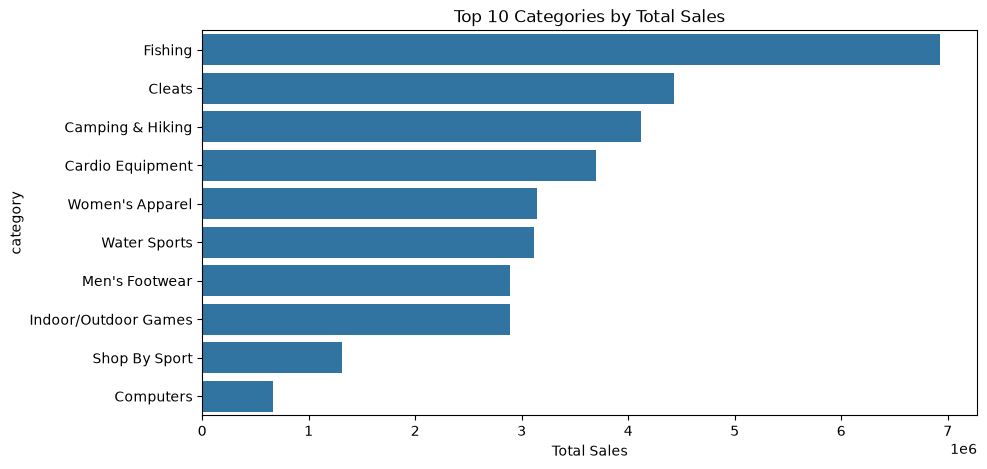

In [19]:
cat_perf = df_clean.groupby('category').agg(sales=('sales','sum'), profit=('profit_per_order','sum')).sort_values('sales', ascending=False)
dept_perf = df_clean.groupby('department').agg(sales=('sales','sum'), profit=('profit_per_order','sum')).sort_values('sales', ascending=False)

plt.figure(figsize=(10,5))
sns.barplot(data=cat_perf.head(10).reset_index(), x='sales', y='category')
plt.title('Top 10 Categories by Total Sales')
plt.xlabel('Total Sales')
plt.savefig('Top 10 Categories by Total Sales.png')
plt.show()

#### Insights and Recommendations

Category level sales are concentrated in a small number of categories at the top of the chart, well ahead of the rest. Recommendation: treat the top few categories as the ones to protect and invest in first, for example through better inventory availability, since they carry a disproportionate share of total sales.

**Q3. Which individual products generate the highest sales and profit?**


In [20]:
prod_perf = df_clean.groupby('product_name').agg(
    sales=('sales','sum'), profit=('profit_per_order','sum'), quantity=('quantity','sum')
).sort_values('sales', ascending=False)

prod_perf.head(10)

,sales,profit,quantity
product_name,,,
Field & Stream Sportsman 16 Gun Fire Safe,6.929654e+06,756220.767190,17325
Perfect Fitness Perfect Rip Deck,4.421143e+06,493828.299782,73698
Diamondback Women's Serene Classic Comfort Bi,4.118426e+06,427455.568106,13729
Nike Men's Free 5.0+ Running Shoe,3.667633e+06,379915.818503,36680
Nike Men's Dri-FIT Victory Golf Polo,3.147800e+06,350421.029567,62956
Pelican Sunstream 100 Kayak,3.099845e+06,324076.370020,15500
Nike Men's CJ Elite 2 TD Football Cleat,2.891758e+06,311902.820214,22246
O'Brien Men's Neoprene Life Vest,2.888994e+06,318451.430554,57803
Under Armour Girls' Toddler Spine Surge Runni,1.269083e+06,126278.510299,31735


#### Insights and Recommendations

A single product stands out as the top seller by a clear margin. Recommendation: check that product's stock and shipping performance specifically, since any disruption to it would have an outsized effect on total sales given how concentrated the top of this list is.

## Exploratory Data Analysis: Customer

**Q4. How does commercial performance differ across customer segments?**

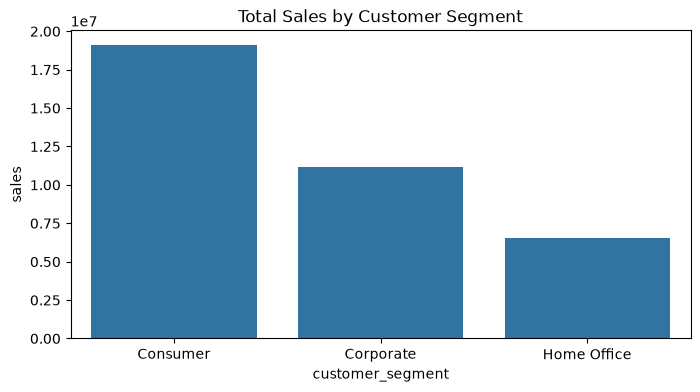

,sales,profit,orders,quantity,avg_discount
customer_segment,,,,,
Consumer,1.909579e+07,2.073488e+06,34119,199234,0.101616
Corporate,1.116841e+07,1.202575e+06,19856,116560,0.101649
Home Office,6.520538e+06,6.908403e+05,11777,68285,0.101851


In [21]:
seg_perf = df_clean.groupby('customer_segment').agg(
    sales=('sales','sum'), profit=('profit_per_order','sum'),
    orders=('order_id','nunique'), quantity=('quantity','sum'),
    avg_discount=('discount_rate','mean')
)

plt.figure(figsize=(8,4))
sns.barplot(data=seg_perf.reset_index(), x='customer_segment', y='sales')
plt.title('Total Sales by Customer Segment')
plt.savefig('Total Sales by Customer Segment')
plt.show()

seg_perf

#### Insights and Recommendations

One segment clearly outweighs the other two in total sales. Recommendation: since this segment already drives most of the volume, retention focused offers aimed at this segment are likely to matter more than acquisition spend aimed at the smaller segments, at least based on sales volume alone.

## Exploratory Data Analysis: Geography

**Q5. Which markets and regions generate the highest sales and profit?**

In [22]:
market_perf = df_clean.groupby('market').agg(sales=('sales','sum'), profit=('profit_per_order','sum')).sort_values('sales', ascending=False)
region_perf = df_clean.groupby('order_region').agg(sales=('sales','sum'), profit=('profit_per_order','sum')).sort_values('sales', ascending=False)

fig = px.bar(market_perf.reset_index(), x='market', y='sales', title='Total Sales by Market',
             labels={'sales':'Total Sales ($)'})

fig.write_image('total_sales_by_market.png', scale=3)

fig.show()

**Insights and Recommendations**

Sales are not evenly spread across markets, with one market clearly ahead of the others. Recommendation: weight any market-specific logistics investment toward the top market first, but confirm the shipping delay rate for that same market before assuming it is also the easiest market to serve, since a high sales market is not automatically a well served one.

## Exploratory Data Analysis: Shipping

**Q6. How does shipment performance differ across shipping modes?**

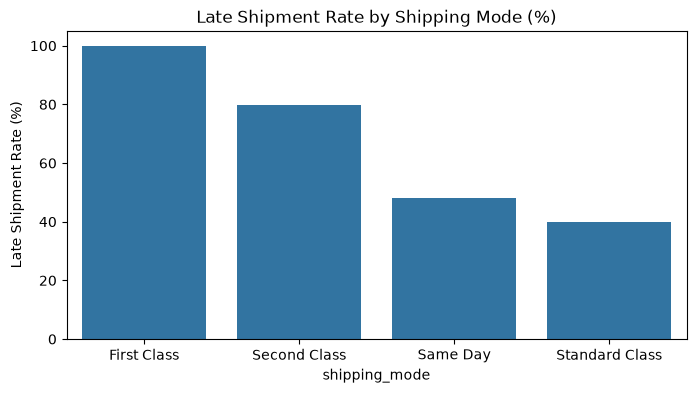

,avg_actual,avg_scheduled,avg_variance,late_rate_pct
shipping_mode,,,,
First Class,2.000000,1.0,1.000000,100.000000
Second Class,3.993167,2.0,1.993167,79.829024
Same Day,0.479285,0.0,0.479285,47.928548
Standard Class,3.993699,4.0,-0.006301,39.769081


In [23]:
mode_perf = eligible.groupby('shipping_mode').agg(
    avg_actual=('actual_shipping_days','mean'),
    avg_scheduled=('scheduled_shipping_days','mean'),
    avg_variance=('shipping_variance','mean'),
    late_rate_pct=('late_delivery_risk', lambda s: s.mean()*100)
).sort_values('late_rate_pct', ascending=False)

plt.figure(figsize=(8,4))
sns.barplot(data=mode_perf.reset_index(), x='shipping_mode', y='late_rate_pct')
plt.title('Late Shipment Rate by Shipping Mode (%)')
plt.ylabel('Late Shipment Rate (%)')
plt.savefig('late_shipment_rate_by_mode.png', dpi=300, bbox_inches='tight')
plt.show()
mode_perf

**Insights and Recommendations**

One shipping mode shows a clearly higher late rate than the others. Recommendation: audit that specific mode's carrier or scheduling assumptions first, since it is dragging down the overall on-schedule rate more than any other single factor identified so far.

**Q7. Which markets and regions have the highest shipment delay rates?**

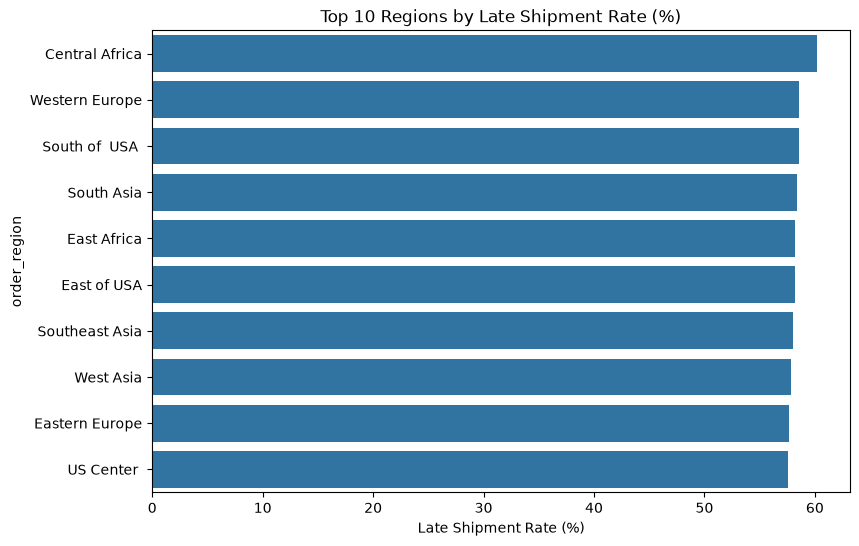

In [24]:
region_delay = (eligible.groupby('order_region')['late_delivery_risk'].mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(9,6))
sns.barplot(x=region_delay.head(10).values, y=region_delay.head(10).index)
plt.title('Top 10 Regions by Late Shipment Rate (%)')
plt.xlabel('Late Shipment Rate (%)')
plt.show()

**Insights and Recommendations**

Delay rates vary meaningfully by region, with the worst region well above the overall average. Recommendation: prioritize any operational fix, such as carrier renegotiation or route review, in the specific regions at the top of this chart rather than applying a blanket policy everywhere.

**Q8. Which product categories experience the highest shipment delay rates?**

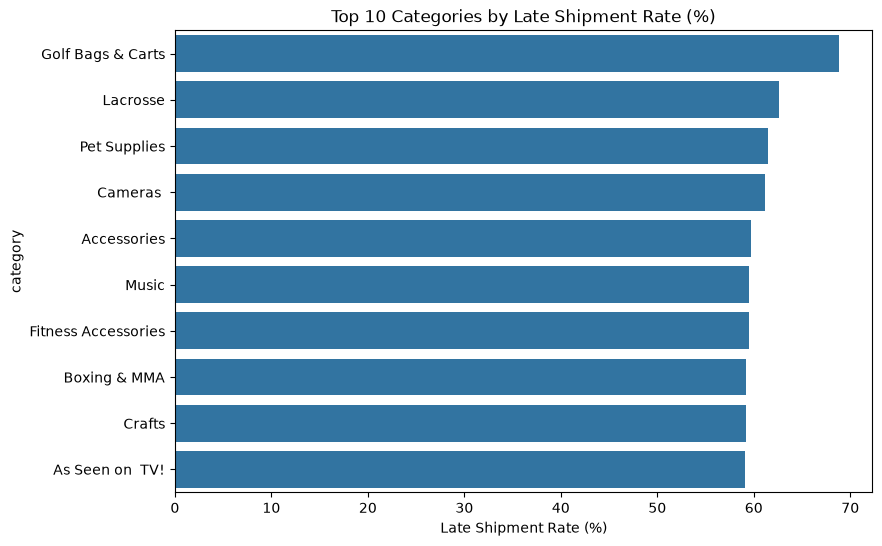

In [25]:
cat_delay = (eligible.groupby('category')['late_delivery_risk'].mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(9,6))
sns.barplot(x=cat_delay.head(10).values, y=cat_delay.head(10).index)
plt.title('Top 10 Categories by Late Shipment Rate (%)')
plt.xlabel('Late Shipment Rate (%)')
plt.show()

**Insights and Recommendations**

Certain categories show a noticeably higher delay rate than others. Recommendation: cross reference this list against the top selling categories from Q2, since a category that is both high volume and high delay is a more urgent fix than a low volume category with the same delay rate.

## Exploratory Data Analysis: Profitability

**Q9. How is discounting associated with order profitability?**

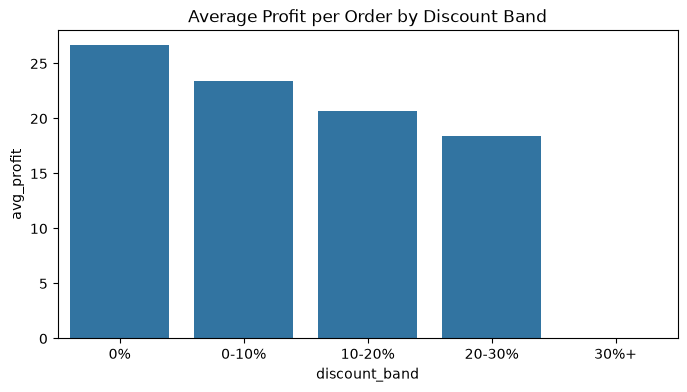

,avg_profit,avg_sales
discount_band,,
0%,26.666574,203.666651
0-10%,23.386170,203.740466
10-20%,20.711490,203.804733
20-30%,18.407092,203.837104


In [26]:
bins = [-0.01, 0, 0.10, 0.20, 0.30, 1.0]
labels = ['0%', '0-10%', '10-20%', '20-30%', '30%+']
df_clean['discount_band'] = pd.cut(df_clean['discount_rate'], bins=bins, labels=labels)

discount_profit = df_clean.groupby('discount_band', observed=True).agg(
    avg_profit=('profit_per_order','mean'), avg_sales=('sales','mean')
)

plt.figure(figsize=(8,4))
sns.barplot(data=discount_profit.reset_index(), x='discount_band', y='avg_profit')
plt.title('Average Profit per Order by Discount Band')
plt.show()

discount_profit

**Insights and Recommendations**

Average profit per order is highest in the no-discount band and does not clearly improve as discounting increases. This is a descriptive pattern only, not proof that discounting itself reduces profit. Recommendation: review discount approval thresholds for the deepest discount bands, and consider a controlled test before assuming discounting should be reduced across the board.

**Q10. Which customer segments generate the highest profit relative to sales?**

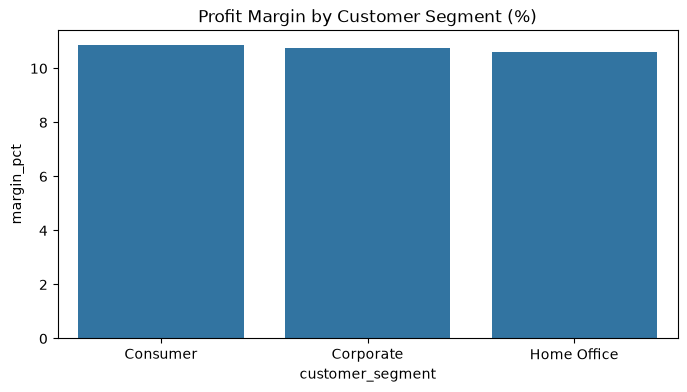

,sales,profit,orders,quantity,avg_discount,margin_pct
customer_segment,,,,,,
Consumer,1.909579e+07,2.073488e+06,34119,199234,0.101616,10.858350
Corporate,1.116841e+07,1.202575e+06,19856,116560,0.101649,10.767650
Home Office,6.520538e+06,6.908403e+05,11777,68285,0.101851,10.594836


In [27]:
seg_perf['margin_pct'] = (seg_perf['profit'] / seg_perf['sales']) * 100

plt.figure(figsize=(8,4))
sns.barplot(data=seg_perf.reset_index(), x='customer_segment', y='margin_pct')
plt.title('Profit Margin by Customer Segment (%)')
plt.show()

seg_perf.sort_values('margin_pct', ascending=False)

**Insights and Recommendations**

The segment with the highest margin is also the segment with the highest total sales identified in Q4, meaning the largest segment is not being subsidized by thinner margins here. Recommendation: this makes the top segment doubly important commercially, both in scale and in profitability, and a reasonable candidate for the first Streamlit dashboard page.

## Combined Supply Chain Analysis

**Q11. Are shipment delays associated with differences in order profitability?**

This is an association check only, not a causal claim.

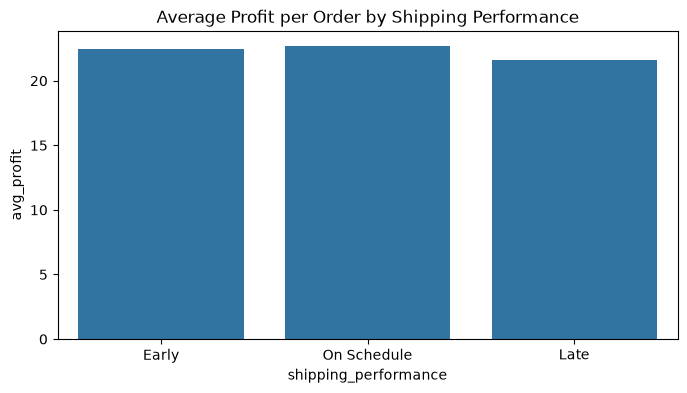

,avg_sales,avg_profit,avg_discount,avg_quantity
shipping_performance,,,,
Early,204.799190,22.485701,0.101690,2.133511
Late,203.344163,21.621707,0.101694,2.127454
On Schedule,204.063439,22.709146,0.101329,2.120916


In [28]:
perf_group = eligible.groupby('shipping_performance').agg(
    avg_sales=('sales','mean'), avg_profit=('profit_per_order','mean'),
    avg_discount=('discount_rate','mean'), avg_quantity=('quantity','mean')
)

plt.figure(figsize=(8,4))
sns.barplot(data=perf_group.reset_index(), x='shipping_performance', y='avg_profit',
            order=['Early','On Schedule','Late'])
plt.title('Average Profit per Order by Shipping Performance')
plt.show()

perf_group

**Insights and Recommendations**

Average profit per order is close across Early, On Schedule and Late shipments, so shipment timing shows little association with per order profit in this dataset. Recommendation: do not use shipment speed as a lever for improving per order profit based on this data alone. If profitability improvement is the goal, the discount band findings in Q9 are a more promising lead than shipping speed.

**Q12. Which combinations of market, shipping mode and product category show the greatest operational risk?**

In [29]:
risk = eligible.groupby(['market','shipping_mode','category']).agg(
    late_rate_pct=('late_delivery_risk', lambda s: s.mean()*100),
    n=('late_delivery_risk','size')
)
risk = risk[risk['n'] >= 30].sort_values('late_rate_pct', ascending=False)
risk.head(10)

late_rate_pct    n
market shipping_mode category                                
USCA   First Class   Women's Apparel               100.0  510
                     Water Sports                  100.0  331
                     Shop By Sport                 100.0  245
                     Men's Footwear                100.0  486
                     Indoor/Outdoor Games          100.0  438
                     Golf Balls                    100.0   31
                     Girls' Apparel                100.0   30
                     Fishing                       100.0  379
                     Electronics                   100.0   90
                     Cleats                        100.0  521

**Insights and Recommendations**

A small number of market, shipping mode and category combinations show a late rate far above the overall average, some approaching the maximum possible rate. Recommendation: treat the combinations at the top of this table as the highest priority operational review list, since they concentrate risk far more than any single dimension, market, mode, or category, viewed on its own.

## Business Insights and Conclusions

Sales are concentrated in a small number of categories and one clearly leading product, with total sales trending upward across the period and one standout peak month.

The Consumer segment leads on both total sales and profit margin, making it the single most important segment commercially.

Europe leads as the top market by sales, but the shipping analysis shows delay risk is not evenly distributed, with specific regions, categories and shipping mode combinations carrying far more risk than others.

Discounting shows no clear profit benefit in this data, with the no-discount band showing the highest average profit per order.

Shipment timing shows little association with per order profit, so speed alone is not a strong lever for improving profitability based on this dataset.

## Limitations

Dataco's shipment outcomes were very likely generated for teaching purposes, given how uniformly high the overall late rate is. Every finding above is an association within this dataset, not a causal claim, and not a live operational audit of a real company.



In [37]:
# Export the cleaned dataset and key summary tables
df_clean.to_csv('C:/Users/SEB/Downloads/PYTHON/PYTHON FOR DATA ANALYTICS & DATA APPS/DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS/Processed/cleaned_dataco.csv', index=False)
kpi_table.to_csv('C:/Users/SEB/Downloads/PYTHON/PYTHON FOR DATA ANALYTICS & DATA APPS/DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS/Outputs/kpi_summary.csv', index=False)
cat_perf.to_csv('C:/Users/SEB/Downloads/PYTHON/PYTHON FOR DATA ANALYTICS & DATA APPS/DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS/Outputs/category_performance.csv')
seg_perf.to_csv('C:/Users/SEB/Downloads/PYTHON/PYTHON FOR DATA ANALYTICS & DATA APPS/DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS/Outputs/segment_performance.csv')
market_perf.to_csv('C:/Users/SEB/Downloads/PYTHON/PYTHON FOR DATA ANALYTICS & DATA APPS/DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS/Outputs/market_performance.csv')
mode_perf.to_csv('C:/Users/SEB/Downloads/PYTHON/PYTHON FOR DATA ANALYTICS & DATA APPS/DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS/Outputs/shipping_mode_performance.csv')
risk.head(20).to_csv('C:/Users/SEB/Downloads/PYTHON/PYTHON FOR DATA ANALYTICS & DATA APPS/DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS/Outputs/top_risk_combinations.csv')

